# Assignment 5 – Data QA/QC

**Name:** Putri Redita Rositasari  
**Student ID:** 11570018

## Research Question

How does relative humidity (RH) vary with air temperature (AMB_TEMP) in Taiwan?

## Selected Variables

- AMB_TEMP: Air Temperature (°C)
- RH: Relative Humidity (%)

This notebook continues the processed dataset from Assignment 4 and
evaluates its data quality using scientifically defensible QA/QC rules.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/analysis_ready_temperature_humidity (1).csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (476, 6)


,siteid,sitename,county,monitordate,AMB_TEMP,RH
0,1,基隆,基隆市,10/14/2026 15:00,27.4,65
1,1,基隆,基隆市,10/14/2026 16:00,26.5,71
2,1,基隆,基隆市,10/14/2026 17:00,26.0,73
3,1,基隆,基隆市,10/14/2026 18:00,25.3,79
4,1,基隆,基隆市,10/14/2026 19:00,24.8,82


In [2]:
x = df.copy()

# Convert columns to appropriate data types
x["monitordate"] = pd.to_datetime(
    x["monitordate"],
    errors="coerce"
)

x["AMB_TEMP"] = pd.to_numeric(
    x["AMB_TEMP"],
    errors="coerce"
)

x["RH"] = pd.to_numeric(
    x["RH"],
    errors="coerce"
)

print("Total observations:", len(x))

print("\nMissing values:")
print(x[["AMB_TEMP", "RH"]].isna().sum())

print("\nDuplicate site-time observations:")
print(
    x.duplicated(
        subset=["siteid", "monitordate"]
    ).sum()
)

print("\nInvalid timestamps:")
print(x["monitordate"].isna().sum())

print("\nSummary statistics:")
display(x[["AMB_TEMP", "RH"]].describe())

Total observations: 476

Missing values:
AMB_TEMP    0
RH          0
dtype: int64

Duplicate site-time observations:
0

Invalid timestamps:
0

Summary statistics:


,AMB_TEMP,RH
count,476.000000,476.000000
mean,27.203992,64.838235
std,1.954451,9.151651
min,17.600000,36.000000
25%,25.975000,59.000000
50%,27.300000,65.000000
75%,28.600000,71.000000
max,31.100000,95.000000


## QA/QC Rule 1 – Physical Validity of Relative Humidity

Relative humidity is physically bounded between 0% and 100%.
Therefore, RH observations outside this range are considered physically invalid.

Invalid observations are flagged first rather than immediately deleted,
so that the original data remain traceable.

In [3]:
x["flag_invalid_rh"] = (
    (x["RH"] < 0) |
    (x["RH"] > 100)
)

print(
    "RH values outside 0–100%:",
    x["flag_invalid_rh"].sum()
)

display(
    x.loc[
        x["flag_invalid_rh"],
        ["siteid", "sitename", "monitordate",
         "AMB_TEMP", "RH"]
    ]
)

RH values outside 0–100%: 0


,siteid,sitename,monitordate,AMB_TEMP,RH


In [4]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return lower, upper


temp_lower, temp_upper = iqr_bounds(x["AMB_TEMP"])
rh_lower, rh_upper = iqr_bounds(x["RH"])

print(
    "AMB_TEMP IQR bounds:",
    temp_lower, "to", temp_upper
)

print(
    "RH IQR bounds:",
    rh_lower, "to", rh_upper
)

AMB_TEMP IQR bounds: 22.0375 to 32.5375
RH IQR bounds: 41.0 to 89.0


In [5]:
x["flag_temp_outlier"] = (
    (x["AMB_TEMP"] < temp_lower) |
    (x["AMB_TEMP"] > temp_upper)
)

x["flag_rh_outlier"] = (
    (x["RH"] < rh_lower) |
    (x["RH"] > rh_upper)
)

x["flag_potential_outlier"] = (
    x["flag_temp_outlier"] |
    x["flag_rh_outlier"]
)

print(
    "Potential outliers:",
    x["flag_potential_outlier"].sum()
)

Potential outliers: 11


In [6]:
flagged = x[
    x["flag_potential_outlier"]
].copy()

display(
    flagged[
        [
            "siteid",
            "sitename",
            "county",
            "monitordate",
            "AMB_TEMP",
            "RH"
        ]
    ].sort_values("monitordate")
)

,siteid,sitename,county,monitordate,AMB_TEMP,RH
108,25,頭份,苗栗縣,2026-10-14 15:00:00,29.8,36
356,64,陽明,臺北市,2026-10-14 15:00:00,19.2,81
440,80,關山,臺東縣,2026-10-14 15:00:00,29.9,40
109,25,頭份,苗栗縣,2026-10-14 16:00:00,28.6,37
357,64,陽明,臺北市,2026-10-14 16:00:00,18.3,86
358,64,陽明,臺北市,2026-10-14 17:00:00,18.0,89
359,64,陽明,臺北市,2026-10-14 18:00:00,18.0,95
360,64,陽明,臺北市,2026-10-14 19:00:00,17.8,95
47,15,松山,臺北市,2026-10-14 20:00:00,24.6,91
175,35,二林,彰化縣,2026-10-14 20:00:00,25.8,40


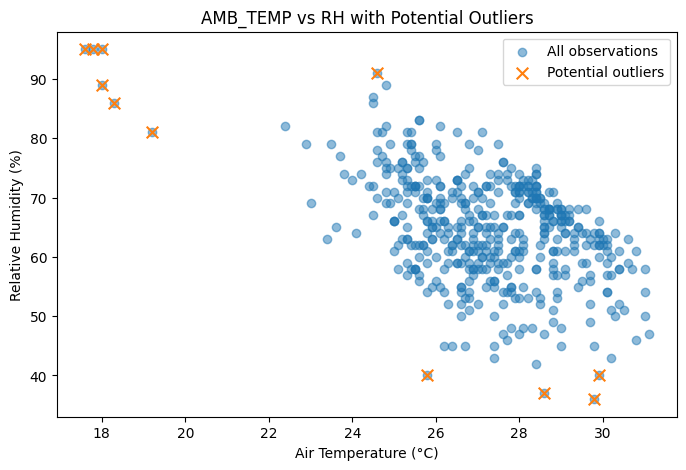

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x["AMB_TEMP"],
    x["RH"],
    alpha=0.5,
    label="All observations"
)

plt.scatter(
    flagged["AMB_TEMP"],
    flagged["RH"],
    marker="x",
    s=70,
    label="Potential outliers"
)

plt.xlabel("Air Temperature (°C)")
plt.ylabel("Relative Humidity (%)")
plt.title("AMB_TEMP vs RH with Potential Outliers")
plt.legend()

plt.show()

## Diagnosis of Potential Outliers

Potential extreme observations were identified using the 1.5 × IQR
criterion. These values were inspected rather than automatically removed.

Statistical outliers are not necessarily measurement errors because
unusual temperature and humidity values may represent genuine
environmental conditions. Therefore, the flagged observations are
retained in the primary dataset and evaluated separately through a
sensitivity analysis.

In [8]:
qaqc_df = x[
    ~x["flag_invalid_rh"]
].copy()

print("Before QA/QC:", len(x))
print("After QA/QC:", len(qaqc_df))
print(
    "Physically invalid observations affected:",
    x["flag_invalid_rh"].sum()
)

Before QA/QC: 476
After QA/QC: 476
Physically invalid observations affected: 0


In [9]:
comparison = pd.DataFrame({
    "Before QA/QC": [
        len(x),
        x["AMB_TEMP"].mean(),
        x["AMB_TEMP"].median(),
        x["RH"].mean(),
        x["RH"].median()
    ],

    "After QA/QC": [
        len(qaqc_df),
        qaqc_df["AMB_TEMP"].mean(),
        qaqc_df["AMB_TEMP"].median(),
        qaqc_df["RH"].mean(),
        qaqc_df["RH"].median()
    ]
},
index=[
    "N",
    "Mean AMB_TEMP",
    "Median AMB_TEMP",
    "Mean RH",
    "Median RH"
])

display(comparison.round(3))

,Before QA/QC,After QA/QC
N,476.000,476.000
Mean AMB_TEMP,27.204,27.204
Median AMB_TEMP,27.300,27.300
Mean RH,64.838,64.838
Median RH,65.000,65.000


In [10]:
correlation_all = qaqc_df[
    "AMB_TEMP"
].corr(
    qaqc_df["RH"]
)

print(
    "Correlation using all valid observations:",
    correlation_all
)

Correlation using all valid observations: -0.4999246364517137


In [11]:
sensitivity_df = qaqc_df[
    ~qaqc_df["flag_potential_outlier"]
].copy()

correlation_without_outliers = (
    sensitivity_df["AMB_TEMP"]
    .corr(sensitivity_df["RH"])
)

print(
    "Correlation excluding potential outliers:",
    correlation_without_outliers
)

print(
    "Observations temporarily excluded:",
    len(qaqc_df) - len(sensitivity_df)
)

Correlation excluding potential outliers: -0.4085056857504346
Observations temporarily excluded: 11


In [12]:
sensitivity = pd.DataFrame({
    "Scenario": [
        "All valid observations",
        "Potential outliers temporarily excluded"
    ],

    "N": [
        len(qaqc_df),
        len(sensitivity_df)
    ],

    "Mean AMB_TEMP": [
        qaqc_df["AMB_TEMP"].mean(),
        sensitivity_df["AMB_TEMP"].mean()
    ],

    "Mean RH": [
        qaqc_df["RH"].mean(),
        sensitivity_df["RH"].mean()
    ],

    "Correlation (r)": [
        correlation_all,
        correlation_without_outliers
    ]
})

display(sensitivity.round(3))

,Scenario,N,Mean AMB_TEMP,Mean RH,Correlation (r)
0,All valid observations,476,27.204,64.838,-0.500
1,Potential outliers temporarily excluded,465,27.315,64.684,-0.409


In [13]:
audit_table = pd.DataFrame({
    "QA/QC Check": [
        "Assignment 4 processed dataset",
        "Missing AMB_TEMP or RH",
        "Invalid RH outside 0–100%",
        "Potential IQR outliers",
        "Primary QA/QC dataset"
    ],

    "Number of Observations": [
        len(x),
        int(
            x[["AMB_TEMP", "RH"]]
            .isna()
            .any(axis=1)
            .sum()
        ),
        int(x["flag_invalid_rh"].sum()),
        int(x["flag_potential_outlier"].sum()),
        len(qaqc_df)
    ],

    "Decision": [
        "Starting dataset",
        "Document",
        "Exclude if physically invalid",
        "Flag and retain",
        "Use for primary analysis"
    ]
})

audit_table

,QA/QC Check,Number of Observations,Decision
0,Assignment 4 processed dataset,476,Starting dataset
1,Missing AMB_TEMP or RH,0,Document
2,Invalid RH outside 0–100%,0,Exclude if physically invalid
3,Potential IQR outliers,11,Flag and retain
4,Primary QA/QC dataset,476,Use for primary analysis


In [15]:
x.to_csv(
    "qaqc_temperature_humidity.csv",
    index=False,
    encoding="utf-8-sig"
)

audit_table.to_csv(
    "qaqc_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

sensitivity.to_csv(
    "qaqc_sensitivity.csv",
    index=False,
    encoding="utf-8-sig"
)

print("QA/QC outputs saved with Excel-compatible UTF-8 encoding.")

QA/QC outputs saved with Excel-compatible UTF-8 encoding.


## Short Interpretation

The most important data-quality issue was the presence of 11 potential outliers in air temperature and/or relative humidity. No missing values or physically invalid RH values were found, so all 476 observations were retained in the primary QA/QC dataset. When the 11 flagged observations were temporarily excluded for sensitivity analysis, the correlation between AMB_TEMP and RH changed from r = -0.500 to r = -0.409. The relationship remained negative, although its strength became weaker, indicating that the results are somewhat sensitive to extreme observations. Uncertainty remains as to whether the flagged observations represent genuine extreme environmental conditions or measurement-related anomalies.